In [1]:
from pathlib import Path
import pandas as pd

# Project root
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"

CLASS_DIRS = {
    "normal": DATA_DIR / "normal",
    "irf": DATA_DIR / "irf",
    "orf": DATA_DIR / "orf",
}

for class_name, folder in CLASS_DIRS.items():
    files = sorted(folder.glob("*.csv"))

    print(f"\n{class_name.upper()}")
    print("-" * 40)
    print("Folder:", folder)
    print("Number of CSV files:", len(files))

    if files:
        sample = pd.read_csv(files[0], header=None)

        print("First file:", files[0].name)
        print("Shape:", sample.shape)
        print("First 5 values:")
        print(sample.head().to_string(index=False, header=False))


NORMAL
----------------------------------------
Folder: c:\Users\asus\OneDrive\Desktop\siamese-network\data\normal
Number of CSV files: 100
First file: S_N(854).csv
Shape: (100000, 1)
First 5 values:
0.001984
0.001984
0.001831
0.001984
0.002136

IRF
----------------------------------------
Folder: c:\Users\asus\OneDrive\Desktop\siamese-network\data\irf
Number of CSV files: 100
First file: S_IR(895).csv
Shape: (100000, 1)
First 5 values:
-0.002136
-0.002441
-0.002899
-0.003204
-0.003052

ORF
----------------------------------------
Folder: c:\Users\asus\OneDrive\Desktop\siamese-network\data\orf
Number of CSV files: 100
First file: S_OR(52).csv
Shape: (100000, 1)
First 5 values:
-0.003357
-0.003204
-0.003357
-0.003510
-0.003510


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = PROJECT_ROOT / "datasets" / "raw"

RAW_DIR.mkdir(parents=True, exist_ok=True)

CLASS_DIRS = {
    "normal": DATA_DIR / "normal",
    "irf": DATA_DIR / "irf",
    "orf": DATA_DIR / "orf",
}


def load_class(folder):
    """
    Load every CSV in a class folder.

    Each CSV = one complete signal.
    Returns:
        X: shape (number_of_signals, number_of_samples)
        filenames: corresponding CSV filenames
    """
    
    files = sorted(folder.glob("*.csv"))

    signals = []
    
    for file in files:
        signal = pd.read_csv(file, header=None).values.squeeze()

        signals.append(signal)

    X = np.asarray(signals, dtype=np.float32)

    return X, [f.name for f in files]


datasets = {}
file_names = {}

for class_name, folder in CLASS_DIRS.items():
    X, names = load_class(folder)

    datasets[class_name] = X
    file_names[class_name] = names

    print(f"{class_name.upper()}: {X.shape}")

NORMAL: (100, 100000)
IRF: (100, 100000)
ORF: (100, 100000)


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = PROJECT_ROOT / "datasets" / "raw"

RAW_DIR.mkdir(parents=True, exist_ok=True)

CLASS_DIRS = {
    "normal": DATA_DIR / "normal",
    "irf": DATA_DIR / "irf",
    "orf": DATA_DIR / "orf",
}


def load_class(folder):
    """
    Load every CSV in a class folder.

    Each CSV = one complete signal.
    Returns:
        X: shape (number_of_signals, number_of_samples)
        filenames: corresponding CSV filenames
    """
    
    files = sorted(folder.glob("*.csv"))

    signals = []
    
    for file in files:
        signal = pd.read_csv(file, header=None).values.squeeze()

        signals.append(signal)

    X = np.asarray(signals, dtype=np.float32)

    return X, [f.name for f in files]


datasets = {}
file_names = {}

for class_name, folder in CLASS_DIRS.items():
    X, names = load_class(folder)

    datasets[class_name] = X
    file_names[class_name] = names

    print(f"{class_name.upper()}: {X.shape}")

NORMAL: (100, 100000)
IRF: (100, 100000)
ORF: (100, 100000)


In [4]:
for class_name, X in datasets.items():

    output_file = RAW_DIR / f"{class_name}.csv"

    pd.DataFrame(X).to_csv(
        output_file,
        index=False,
        header=False
    )

    print(f"Saved: {output_file}")

Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\raw\normal.csv
Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\raw\irf.csv
Saved: c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\raw\orf.csv


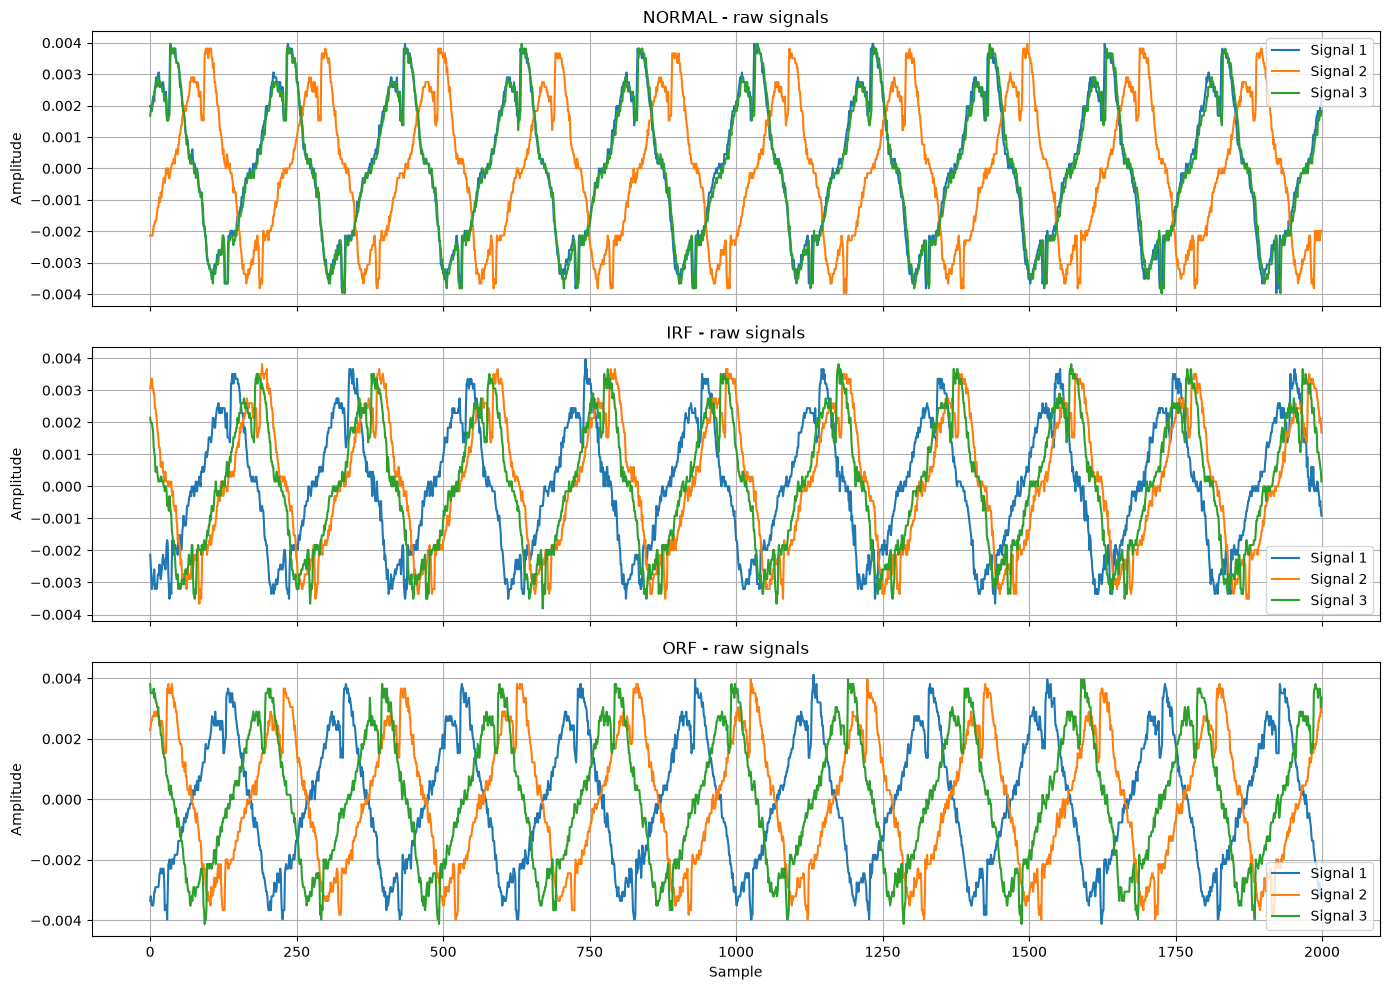

: 

In [ ]:
import matplotlib.pyplot as plt

N_SAMPLES_TO_DISPLAY = 2000
N_SIGNALS = 3

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

for ax, class_name in zip(axes, ["normal", "irf", "orf"]):

    X = datasets[class_name]

    for i in range(N_SIGNALS):
        ax.plot(
            X[i, :N_SAMPLES_TO_DISPLAY],
            label=f"Signal {i+1}"
        )

    ax.set_title(f"{class_name.upper()} - raw signals")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    ax.legend()

axes[-1].set_xlabel("Sample")

plt.tight_layout()

FIG_DIR = PROJECT_ROOT / "datasets" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIG_DIR / "raw_signals_first_2000.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()